In [ ]:
from google.colab import files
uploaded = files.upload()

Saving train.csv to train (2).csv


In [ ]:
import pandas as pd

df = pd.read_csv('train.csv')
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


In [ ]:
print("Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())
print("\nMissing Values:")
print(df.isnull().sum())

Shape: (9800, 18)

Column Names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales']

Missing Values:
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
dtype: int64


Category
Technology         827455.8730
Furniture          728658.5757
Office Supplies    705422.3340
Name: Sales, dtype: float64


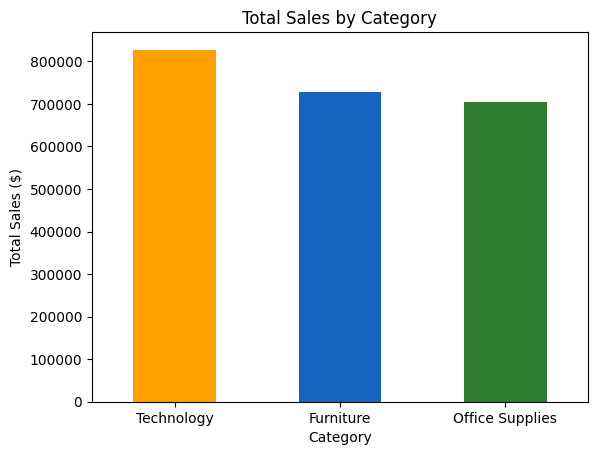

In [ ]:
import matplotlib.pyplot as plt

category_sales = df.groupby('Category')['Sales'].sum().sort_values(ascending=False)
print(category_sales)

category_sales.plot(kind='bar', color=['#FFA000', '#1565C0', '#2E7D32'])
plt.title('Total Sales by Category')
plt.ylabel('Total Sales ($)')
plt.xlabel('Category')
plt.xticks(rotation=0)
plt.show()

**Observation:** The top-selling products are mostly high-value office equipment (copiers, binding machines, printers), indicating these items contribute more to revenue through higher price points rather than high sales volume.

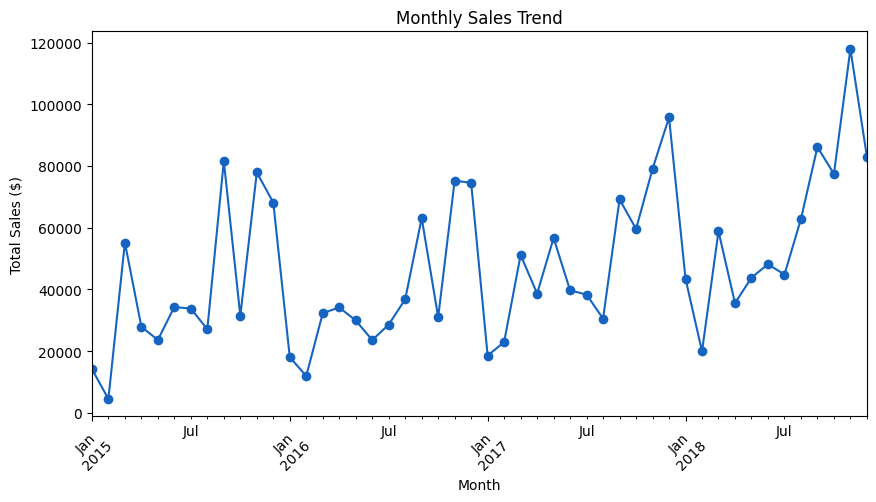

In [ ]:
df['Order Date'] = pd.to_datetime(df['Order Date'], format='%d/%m/%Y')
df['Month'] = df['Order Date'].dt.to_period('M')

monthly_sales = df.groupby('Month')['Sales'].sum()

monthly_sales.plot(kind='line', figsize=(10,5), color='#1565C0', marker='o')
plt.title('Monthly Sales Trend')
plt.ylabel('Total Sales ($)')
plt.xlabel('Month')
plt.xticks(rotation=45)
plt.show()

**Observation:** Monthly sales show seasonal fluctuations with an overall upward trend from 2015 to 2018, with notable peaks likely corresponding to holiday shopping periods (Nov-Dec).

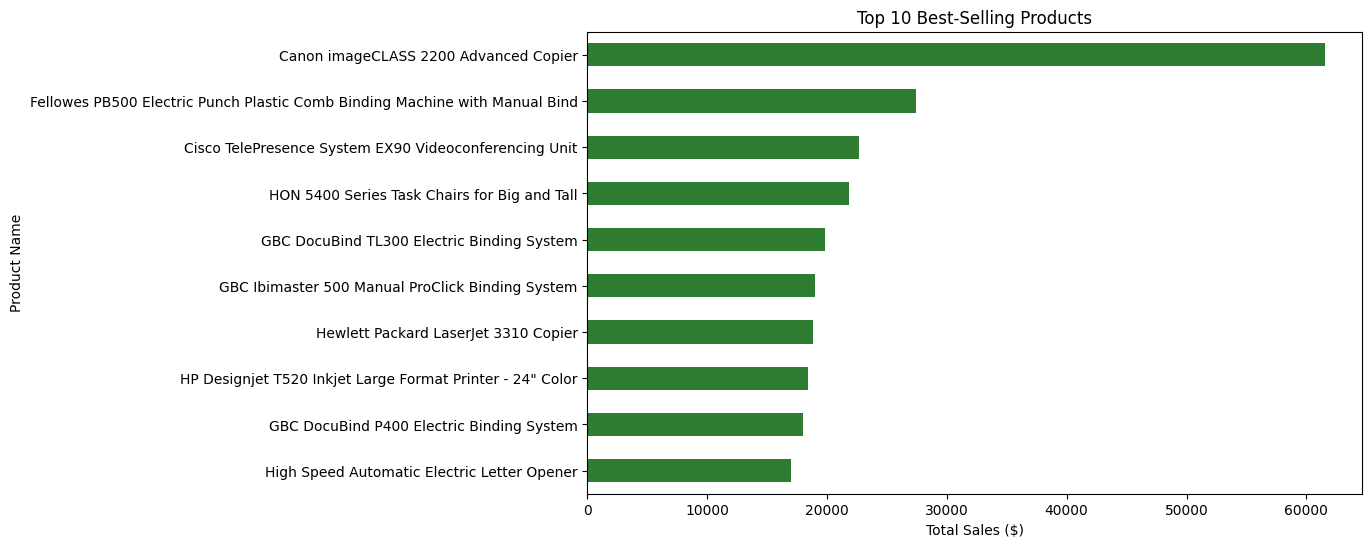

In [ ]:
top_products = df.groupby('Product Name')['Sales'].sum().sort_values(ascending=False).head(10)

top_products.plot(kind='barh', figsize=(10,6), color='#2E7D32')
plt.title('Top 10 Best-Selling Products')
plt.xlabel('Total Sales ($)')
plt.gca().invert_yaxis()
plt.show()

**Observation:** Technology products generated the highest total sales (USD 827K), followed by Furniture (USD 728K) and Office Supplies (USD 705K). This suggests technology items likely have higher individual price points even if sold in smaller quantities.

Region
West       710219.6845
East       669518.7260
Central    492646.9132
South      389151.4590
Name: Sales, dtype: float64


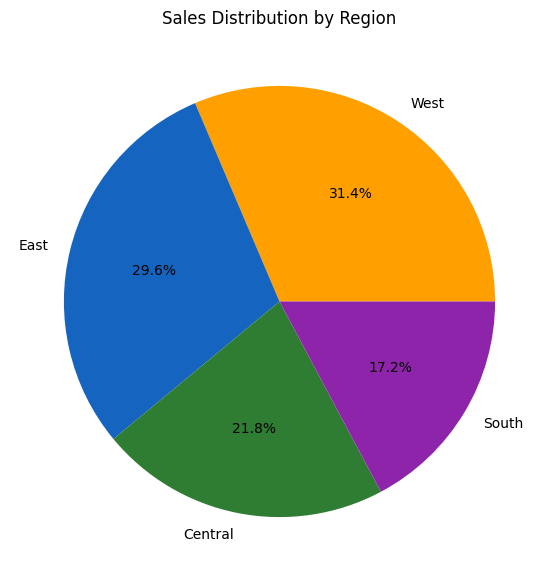

In [ ]:
region_sales = df.groupby('Region')['Sales'].sum().sort_values(ascending=False)
print(region_sales)

region_sales.plot(kind='pie', autopct='%1.1f%%', figsize=(7,7),
                   colors=['#FFA000', '#1565C0', '#2E7D32', '#8E24AA'])
plt.title('Sales Distribution by Region')
plt.ylabel('')
plt.show()

**Observation:** The West region leads in sales contribution (31.4%), followed by East, Central, and South. This suggests the business has stronger market penetration or customer demand in the West, which could guide targeted marketing or inventory allocation strategies for other underperforming regions.

## Conclusion

This exploratory data analysis of retail sales data revealed the following key insights:

1. **Category Performance:** Technology products generated the highest total sales, followed closely by Furniture and Office Supplies.

2. **Seasonal Trends:** Monthly sales showed clear seasonal fluctuations with an overall upward trend from 2015 to 2018, likely driven by holiday shopping periods.

3. **Top Products:** High-value office equipment (copiers, binding machines, printers) dominated the top-selling products list, indicating these items drive revenue through higher price points.

4. **Regional Distribution:** The West region contributed the largest share of sales (31.4%), followed by East, Central, and South, highlighting a geographic concentration of demand.

**Business Recommendations:**
- Focus marketing efforts on boosting sales in the South and Central regions.
- Consider bundling high-margin Technology products with Office Supplies to increase average order value.
- Plan inventory and promotional campaigns around the identified seasonal peaks (Nov-Dec).